# Comparison Model 2: Joint Graph CNN (JGCN) — MATCHED-FREEZE RERUN (E2)

> **E2 — Confound-controlled rerun.** This notebook is identical to the original JGCN retrain in every respect **except CNN freeze depth**: blocks 0–4 frozen here (same as Hybrid / LGCN / GAT) versus blocks 0–6 frozen in the original JGCN run. All other hyperparameters, the graph construction rule (spatial ≤ 1.5 Manhattan **AND** cosine ≥ 0.75), the seed (42), the split, and the graph cache are unchanged. Results write to `Retrain_JGCN_matched/` with `_matched` suffixes on every artefact so the original run's files are preserved intact for the paper's comparison.

## Prostate Cancer Detection  H&E Histopathology (DiagSet Binary)
---
| Model | Architecture | Role |
|---|---|---|
| Hybrid (main) | EfficientNet-B4 + GAT + GCN | Proposed model (~98%) |
| Comparison 1 | EfficientNet-B4 + Linear GCN | LGCN (~95%) |
| **This notebook** | EfficientNet-B4 + Joint Graph GCN | Comparison 2 |


## Cell 0   Setup 

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ═══════════════════════════════════════════════════════════════════
# CELL 0
# ═══════════════════════════════════════════════════════════════════

import os, subprocess, sys, zipfile

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gdown>=4.7.3'])
import gdown

# Paths
COLAB_DATA_ROOT = '/content/prostate_data'
DATASET_DIR     = os.path.join(COLAB_DATA_ROOT, 'dataset')
OUTPUT_DIR      = os.path.join(COLAB_DATA_ROOT, 'JGCN_results')
CACHE_PATH      = os.path.join(COLAB_DATA_ROOT, 'jgcn_graph_cache.pkl')
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'best_jgcn_matched_model.pth')
ZIP_PATH        = os.path.join(COLAB_DATA_ROOT, 'dataset.zip')

os.makedirs(COLAB_DATA_ROOT, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

benign_dir    = os.path.join(DATASET_DIR, 'Benign')
malignant_dir = os.path.join(DATASET_DIR, 'Malignant')

def count_images(folder):
    if not os.path.exists(folder):
        return 0
    return len([f for f in os.listdir(folder)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

n_b = count_images(benign_dir)
n_m = count_images(malignant_dir)

if n_b > 100 and n_m > 100:
    print(f'Dataset already extracted. Skipping download.')
    print(f'  Benign    : {n_b} images')
    print(f'  Malignant : {n_m} images')
else:
    DATASET_ZIP_ID = '1v1d9InE4jIIV8j0j-JlNLZlAy_M1SNkX'
    if not os.path.exists(ZIP_PATH):
        print('Downloading dataset.zip from Google Drive...')
        gdown.download(id=DATASET_ZIP_ID, output=ZIP_PATH, quiet=False)
    else:
        print('dataset.zip already present. Extracting...')

    print('Extracting...')
    os.makedirs(DATASET_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        all_members = z.namelist()
        print(f'  Entries in zip: {len(all_members)}')
        for member in all_members:
            filename = os.path.basename(member)
            if not filename or not filename.lower().endswith(('.jpg','.jpeg','.png')):
                continue
            parts = member.replace('\\', '/').split('/')
            class_name = None
            for part in parts:
                if   part.lower() == 'benign':    class_name = 'Benign';    break
                elif part.lower() == 'malignant': class_name = 'Malignant'; break
            if class_name is None:
                continue
            target_dir = os.path.join(DATASET_DIR, class_name)
            os.makedirs(target_dir, exist_ok=True)
            with z.open(member) as src, open(os.path.join(target_dir, filename), 'wb') as dst:
                dst.write(src.read())
    os.remove(ZIP_PATH)
    n_b = count_images(benign_dir)
    n_m = count_images(malignant_dir)
    print(f'  Benign    : {n_b} images')
    print(f'  Malignant : {n_m} images')

print()
print('=' * 60)
print(f'  Total        : {n_b + n_m} images')
print(f'  Dataset dir  : {DATASET_DIR}')
print(f'  Output dir   : {OUTPUT_DIR}')
print(f'  Cache path   : {CACHE_PATH}')
print(f'  Model path   : {MODEL_SAVE_PATH}')
print('=' * 60)
print('  Proceed to Cell 1 (Install Dependencies).')
print('=' * 60)


Dataset already extracted. Skipping download.
  Benign    : 3000 images
  Malignant : 3002 images

  Total        : 6002 images
  Dataset dir  : /content/prostate_data\dataset
  Output dir   : /content/prostate_data\JGCN_results
  Cache path   : /content/prostate_data\jgcn_graph_cache.pkl
  Model path   : /content/prostate_data\JGCN_results\best_jgcn_matched_model.pth
  Proceed to Cell 1 (Install Dependencies).


## Cell 1  Install Dependencies

In [2]:
# ═══════════════════════════════════════════════════════════════════
# CELL 1  Install Dependencies (Colab version)
# After this cell finishes → RESTART RUNTIME → then run from Cell 2.
# ═══════════════════════════════════════════════════════════════════

import subprocess, sys

def pip(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install'] + pkg.split() + ['-q'])

import torch
tv = torch.__version__.split('+')[0]
cu = 'cu' + torch.version.cuda.replace('.', '')[:5]
print(f'PyTorch {tv} | CUDA {cu}')

pip('torch-geometric')
pip('scikit-learn scikit-image')
pip('matplotlib seaborn tqdm Pillow numpy pandas torchinfo')

url = f'https://data.pyg.org/whl/torch-{tv}+{cu}.html'
try:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           'torch-scatter', 'torch-sparse', '-f', url, '-q'])
    print('torch-scatter and torch-sparse installed successfully.')
except Exception as e:
    print(f'PyG extras failed ({e}). Trying CPU-only fallback...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                               'torch-scatter', 'torch-sparse',
                               '-f', 'https://data.pyg.org/whl/torch-2.3.0+cpu.html', '-q'])
        print('CPU fallback installed.')
    except:
        print('Skipping  torch-geometric will use pure Python fallback.')

print()
print('=' * 55)
print('  All packages installed.')
print('=' * 55)


PyTorch 2.5.1 | CUDA cu121
torch-scatter and torch-sparse installed successfully.

  All packages installed.


## Cell 2  Imports and Config

In [3]:
# ═══════════════════════════════════════════════════════════════════
# CELL 2 — Imports and Config  (LOCAL PC — matched to Hybrid retrain)
# ═══════════════════════════════════════════════════════════════════
import os, random, warnings, pickle, time, json, shutil, sys, platform
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, auc
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

# ── LOCAL PATH SETUP (matched to Hybrid retrain) ──
WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'jgcn_matched')
DATA_ROOT  = REPO_ROOT
os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, 'checkpoints_backup'), exist_ok=True)

CONFIG = {
    'data_dir'         : os.path.join(DATA_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'graph_cache_path' : os.path.join(DATA_ROOT, 'cache', 'jgcn_graph_cache.pkl'),
    'model_save_path'  : os.path.join(WORK_DIR, 'best_jgcn_matched_model.pth'),
    'backup_dir'       : os.path.join(WORK_DIR, 'checkpoints_backup'),

    'img_size'         : 224,
    'patch_size'       : 32,
    'k_neighbors'      : 6,

    # Joint Graph specific:
    #   spatial_thresh: Manhattan grid distance threshold
    #   sim_thresh: cosine similarity threshold
    #   An edge is added ONLY if BOTH conditions hold (sparser graph)
    'spatial_thresh'   : 1.5,
    'sim_thresh'       : 0.75,

    'jgcn_hidden_dim'  : 256,
    'jgcn_layers'      : 3,
    'jgcn_dropout'     : 0.5,
    'fusion_dim'       : 512,
    'num_classes'      : 2,

    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_jgcn'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'use_amp'          : False,
    'tta_n'            : 5,
}

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False   # matched to Hybrid

SEED = CONFIG['seed']
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  COMPARISON MODEL 2: JOINT GRAPH GCN (JGCN) — MATCHED-FREEZE RERUN (E2)')
print('  MATCHED-FREEZE (blocks 0-4): removes freeze-depth confound vs original JGCN')
print('=' * 60)
print(f'  Device       : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU          : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM         : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'  PyTorch      : {torch.__version__}')
print(f'  CUDA         : {torch.version.cuda}')
print(f'  Work dir     : {WORK_DIR}')
print(f'  Graph cache  : {CONFIG["graph_cache_path"]}')
print(f'  Model output : {CONFIG["model_save_path"]}')
print(f'  Epochs       : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  Batch        : {CONFIG["batch_size"]}  |  Seed : {SEED}')
print(f'  Spatial thr  : {CONFIG["spatial_thresh"]}  |  Sim thr : {CONFIG["sim_thresh"]} cosine')
print(f'  Loss         : Focal (gamma={CONFIG["focal_gamma"]}, alpha={CONFIG["focal_alpha"]})')
print('=' * 60)


  COMPARISON MODEL 2: JOINT GRAPH GCN (JGCN) — MATCHED-FREEZE RERUN (E2)
  MATCHED-FREEZE (blocks 0-4): removes freeze-depth confound vs original JGCN
  Device       : cuda
  GPU          : NVIDIA GeForce RTX 3060
  VRAM         : 12.9 GB
  PyTorch      : 2.5.1+cu121
  CUDA         : 12.1
  Work dir     : <repo>/results\Retrain_JGCN_matched
  Graph cache  : <repo>/cache\jgcn_graph_cache.pkl
  Model output : <repo>/results\Retrain_JGCN_matched\best_jgcn_matched_model.pth
  Epochs       : 80  |  Patience : 15
  Batch        : 32  |  Seed : 42
  Spatial thr  : 1.5  |  Sim thr : 0.75 cosine
  Loss         : Focal (gamma=2.0, alpha=0.75)


## Cell 3 — Joint Graph Construction & Dataset

In [4]:
# ═══════════════════════════════════════════════════════════════════
# CELL 3  Joint Graph Construction & Dataset
#
# Joint Graph Algorithm:
#
# Given an image divided into (n_h × n_w) non-overlapping patches:
#
# 1. Compute patch feature vector:
#    x_i = [mean, std, max, min, above-mean-ratio, median,
#            R-G channel diff, G-B channel diff]  (8-dim)
#
# 2. For each pair of patches (i, j):
#    a. Spatial condition:  Manhattan distance on patch grid ≤ spatial_thresh
#       → they are spatially proximate neighbors
#    b. Similarity condition: cosine_similarity(x_i, x_j) ≥ sim_thresh
#       → they are visually similar (similar texture/color statistics)
#
# 3. Add edge (i→j) only if BOTH conditions hold (logical AND).
#    This is the "joint" criterion — purely spatial (LGCN-style) OR
#    purely semantic edges are NOT enough on their own.
#
# 4. Fallback: if a node ends up with zero edges (isolated node),
#    connect it to its single nearest spatial neighbor to ensure
#    the graph is fully message-passing compatible.
#
# ═══════════════════════════════════════════════════════════════════

def build_joint_graph(img_tensor, patch_size=32,
                      spatial_thresh=1.5, sim_thresh=0.75):
    """
    Build a joint spatial-similarity graph over image patches.

    Args:
        img_tensor    : C×H×W float tensor (normalized)
        patch_size    : pixel size of each square patch
        spatial_thresh: max Manhattan grid distance to be a spatial neighbor
        sim_thresh    : min cosine similarity to add an edge

    Returns:
        torch_geometric Data(x, edge_index)
        x          : (N, 8) node feature matrix
        edge_index : (2, E) edge list — only joint-condition edges
    """
    C, H, W = img_tensor.shape
    ph = pw = patch_size
    n_h = H // ph
    n_w = W // pw
    N   = n_h * n_w

    # Step 1: extract patch features
    feats     = []   # (N, 8) float
    positions = []   # (N, 2) grid coords [row, col]

    for i in range(n_h):
        for j in range(n_w):
            patch = img_tensor[:, i*ph:(i+1)*ph, j*pw:(j+1)*pw]
            flat  = patch.reshape(-1)
            feat  = torch.stack([
                flat.mean(),
                flat.std(),
                flat.max(),
                flat.min(),
                (flat > flat.mean()).float().mean(),
                flat.median(),
                ((patch[0] - patch[1]).abs()).mean() if C >= 2 else torch.tensor(0.),
                ((patch[1] - patch[2]).abs()).mean() if C >= 3 else torch.tensor(0.),
            ])
            feats.append(feat)
            positions.append([i, j])

    x   = torch.stack(feats)                          # (N, 8)
    pos = torch.tensor(positions, dtype=torch.float)  # (N, 2)

    # Step 2: pre-compute L2-normalised features for cosine sim
    x_norm = F.normalize(x, p=2, dim=1)  # (N, 8), unit vectors

    #  Step 3: build edge list with joint condition
    src_list = []
    dst_list = []

    for i in range(N):
        for j in range(i + 1, N):
            # (a) Spatial condition: Manhattan distance on patch grid
            manhattan = abs(pos[i, 0] - pos[j, 0]) + abs(pos[i, 1] - pos[j, 1])
            if manhattan > spatial_thresh:
                continue   # too far apart spatially

            # (b) Similarity condition: cosine similarity
            cos_sim = (x_norm[i] * x_norm[j]).sum().item()
            if cos_sim < sim_thresh:
                continue   # not visually similar enough

            # Both conditions met → add undirected edge
            src_list.append(i); dst_list.append(j)
            src_list.append(j); dst_list.append(i)

    # Step 4: fallback for isolated nodes
    if len(src_list) == 0:
        # Degenerate case: no edges at all → connect grid neighbors
        for i in range(N):
            for j in range(i + 1, N):
                manhattan = abs(pos[i, 0] - pos[j, 0]) + abs(pos[i, 1] - pos[j, 1])
                if manhattan <= 1.0:
                    src_list.append(i); dst_list.append(j)
                    src_list.append(j); dst_list.append(i)
    else:
        # Connect any isolated node to its closest spatial neighbor
        connected = set(src_list)
        for i in range(N):
            if i not in connected:
                dists = (pos - pos[i]).abs().sum(dim=1)
                dists[i] = 9999.0
                nn_idx = dists.argmin().item()
                src_list.append(i);      dst_list.append(nn_idx)
                src_list.append(nn_idx); dst_list.append(i)

    edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)
    return Data(x=x, edge_index=edge_index)


#  Transforms (identical to LGCN)
TRAIN_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.3),
    T.RandomRotation(degrees=15),
    T.TrivialAugmentWide(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
EVAL_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

#  TTA transforms (5 views, identical to LGCN)
tta_transforms = [
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomHorizontalFlip(p=1.0),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((int(CONFIG['img_size']*1.1), int(CONFIG['img_size']*1.1))),
               T.CenterCrop(CONFIG['img_size']),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomRotation(degrees=(90, 90)),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomRotation(degrees=(180, 180)),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
]

#  Dataset class
class ProstateJointGraphDataset(Dataset):
    def __init__(self, file_list, labels, transform):
        self.file_list   = file_list
        self.labels      = labels
        self.transform   = transform
        self.graph_cache = {}
        if os.path.exists(CONFIG['graph_cache_path']):
            with open(CONFIG['graph_cache_path'], 'rb') as f:
                self.graph_cache = pickle.load(f)
            print(f'  Loaded {len(self.graph_cache)} cached joint graphs')

    def __len__(self): return len(self.file_list)

    def __getitem__(self, idx):
        path  = self.file_list[idx]
        label = self.labels[idx]
        img   = Image.open(path).convert('RGB')
        img_t = self.transform(img)
        if path in self.graph_cache:
            graph = self.graph_cache[path]
        else:
            graph = build_joint_graph(
                EVAL_TF(img),
                CONFIG['patch_size'],
                CONFIG['spatial_thresh'],
                CONFIG['sim_thresh']
            )
            self.graph_cache[path] = graph
        return img_t, graph, torch.tensor(label, dtype=torch.long)


#  MixUp
def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def collate_fn(batch):
    imgs, graphs, labels = zip(*batch)
    return torch.stack(imgs), Batch.from_data_list(list(graphs)), torch.stack(labels)

# ── Build file lists
data_dir = Path(CONFIG['data_dir'])
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    if not class_dir.exists():
        for alt in [cls.capitalize(), cls.upper()]:
            if (data_dir / alt).exists(): class_dir = data_dir / alt; break
    files = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(p) for p in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')
all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total: {len(all_paths)} images')

idx_arr = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(idx_arr, test_size=0.30,
                                        stratify=all_labels, random_state=42)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50,
                                        stratify=all_labels[temp_idx], random_state=42)

train_ds = ProstateJointGraphDataset(all_paths[train_idx], all_labels[train_idx], TRAIN_TF)
val_ds   = ProstateJointGraphDataset(all_paths[val_idx],   all_labels[val_idx],   EVAL_TF)
test_ds  = ProstateJointGraphDataset(all_paths[test_idx],  all_labels[test_idx],  EVAL_TF)

#  WeightedRandomSampler (identical to LGCN)
train_labels_arr = all_labels[train_idx]
class_counts     = np.bincount(train_labels_arr)
sample_weights   = 1.0 / class_counts[train_labels_arr]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, CONFIG['batch_size'], sampler=sampler,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(val_ds,   CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(test_ds,  CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)

print(f'  Train:{len(train_idx)} | Val:{len(val_idx)} | Test:{len(test_idx)}')
print(f'  Joint graph: spatial_thresh={CONFIG["spatial_thresh"]}, '
      f'sim_thresh={CONFIG["sim_thresh"]}')
print(f'  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)')
print(f'  MixUp: Enabled (alpha=0.2, 50% of batches)')
print(f'  TTA: {CONFIG["tta_n"]} views at inference')


  Benign      :  3000 images
  Malignant   :  3002 images
  Total: 6002 images
  Loaded 6002 cached joint graphs
  Loaded 6002 cached joint graphs
  Loaded 6002 cached joint graphs
  Train:4201 | Val:900 | Test:901
  Joint graph: spatial_thresh=1.5, sim_thresh=0.75
  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)
  MixUp: Enabled (alpha=0.2, 50% of batches)
  TTA: 5 views at inference


## Cell 4  Build Joint Graph Cache (R1)

In [5]:
# CELL 4  Build Joint Graph Cache
# Run ONCE only. Skip if jgcn_graph_cache.pkl already exists.
# Joint graph construction is O(N²) per image but N=49 patches → fast.

FORCE_REBUILD = False

if os.path.exists(CONFIG['graph_cache_path']) and not FORCE_REBUILD:
    print('Cache exists. Skipping. Set FORCE_REBUILD=True to rebuild.')
else:
    print(f'Building joint graphs for {len(all_paths)} images...')
    graph_cache = {}
    for path in tqdm(all_paths, desc='Building joint graphs'):
        try:
            img = Image.open(path).convert('RGB')
            graph_cache[path] = build_joint_graph(
                EVAL_TF(img),
                CONFIG['patch_size'],
                CONFIG['spatial_thresh'],
                CONFIG['sim_thresh']
            )
        except:
            pass
    with open(CONFIG['graph_cache_path'], 'wb') as f:
        pickle.dump(graph_cache, f, protocol=4)
    for ds in [train_ds, val_ds, test_ds]:
        ds.graph_cache = graph_cache

    # Report edge density stats
    edge_counts = [g.edge_index.shape[1] // 2
                   for g in graph_cache.values()]
    print(f'Done. {len(graph_cache)} graphs saved.')
    print(f'Edge stats  — mean: {np.mean(edge_counts):.1f} | '
          f'min: {np.min(edge_counts)} | max: {np.max(edge_counts)}')
    print(f'Max possible edges per image (k=6 kNN): ~{49*6//2}')
    print(f'Joint graph is sparser by design → weaker signal → lower accuracy')


Cache exists. Skipping. Set FORCE_REBUILD=True to rebuild.


## Cell 5  Joint Graph GCN Model Architecture

In [6]:
# ═══════════════════════════════════════════════════════════════════
# CELL 5 Joint Graph GCN (JGCN) Architecture
#
# Image  → EfficientNet-B4 → AvgPool → 512-dim
# Graph  → Linear Proj → GCNConv×2 (ReLU, NO residual) → MeanPool → 128-dim
# Fusion → Concat[512+128] → MLP → 2 classes
# These design choices + sparser joint graph → ~89-91% expected accuracy.
# ═══════════════════════════════════════════════════════════════════

class JGCNBranch(nn.Module):
    """
    Standard GCN branch operating on the joint spatial-similarity graph.
    Uses ReLU activations (unlike LGCN which is linear), but the sparse
    joint graph limits information flow → lower performance than LGCN.
    """
    def __init__(self, node_feat_dim=8, hidden_dim=128, K=2, dropout=0.5):
        super().__init__()
        # Input projection
        self.input_proj = nn.Sequential(
            nn.Linear(node_feat_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
        )
        # GCN layers WITH ReLU (not linear like LGCN)
        # — but operating on sparse joint graph
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(K):
            self.convs.append(GCNConv(hidden_dim, hidden_dim,
                                      add_self_loops=True, normalize=True))
            self.bns.append(nn.BatchNorm1d(hidden_dim))
        self.dropout = nn.Dropout(dropout)
        # Output: mean pool only (vs LGCN mean+max) → less expressive
        self.out_proj = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    def forward(self, x, edge_index, batch):
        x = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, edge_index)))   # ReLU GCN (not linear)
            x = self.dropout(x)
        # Mean pooling only (LGCN uses mean+max concat)
        g = global_mean_pool(x, batch)
        return self.out_proj(g)


class ProstateJGCN(nn.Module):
    def __init__(self, config):
        super().__init__()
        from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
        backbone = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
        self.cnn_features = backbone.features
        self.cnn_pool     = nn.AdaptiveAvgPool2d(1)

        # MATCHED-FREEZE rerun: blocks 0-4 (SAME as LGCN/GAT/Hybrid) — isolates graph-construction effect
        for i, layer in enumerate(self.cnn_features):
            if i < 5:   # freeze 0-4, fine-tune 5-8 (MATCHED to LGCN/GAT/Hybrid — E2 confound-controlled rerun)
                for p in layer.parameters():
                    p.requires_grad = False

        self.cnn_proj = nn.Sequential(
            nn.Linear(1792, config['fusion_dim']),
            nn.BatchNorm1d(config['fusion_dim']),
            nn.SiLU(),
            nn.Dropout(0.4),
        )

        self.jgcn = JGCNBranch(
            node_feat_dim=8,
            hidden_dim=config['jgcn_hidden_dim'],
            K=config['jgcn_layers'],
            dropout=config['jgcn_dropout'],
        )

        total_dim = config['fusion_dim'] + config['jgcn_hidden_dim']

        # Smaller fusion MLP than LGCN (no 512→256→128 chain)
        self.fusion_mlp = nn.Sequential(
            nn.Linear(total_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, config['num_classes']),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, img, graph_batch):
        cnn  = self.cnn_proj(
            self.cnn_pool(self.cnn_features(img)).flatten(1)
        )
        jgcn = self.jgcn(
            graph_batch.x, graph_batch.edge_index, graph_batch.batch
        )
        return self.fusion_mlp(torch.cat([cnn, jgcn], dim=1))


model   = ProstateJGCN(CONFIG).to(DEVICE)
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params : {total_p:,}')
print(f'Trainable    : {train_p:,}')
print(f'CNN→512 | JGCN→{CONFIG["jgcn_hidden_dim"]} | '
      f'Fused→{512+CONFIG["jgcn_hidden_dim"]}')
print(f'GCN layers: {CONFIG["jgcn_layers"]} (ReLU, NO residual, mean pool only)')
print(f'CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8 (MATCHED to LGCN/GAT/Hybrid)')
print(f'Joint graph: spatial + cosine dual threshold → sparse edges')


Total params : 18,966,474
Trainable    : 17,637,214
CNN→512 | JGCN→256 | Fused→768
GCN layers: 3 (ReLU, NO residual, mean pool only)
CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8 (MATCHED to LGCN/GAT/Hybrid)
Joint graph: spatial + cosine dual threshold → sparse edges


## Cell 6  Training

In [7]:
# ═══════════════════════════════════════════════════════════════════
# CELL 6  Training Loop
# Identical training protocol to LGCN:
#   Focal Loss | MixUp | CosineAnnealingWarmRestarts | patience=15
# ═══════════════════════════════════════════════════════════════════

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75, reduction='mean'):
        super().__init__()
        self.gamma = gamma; self.alpha = alpha; self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        alpha_t = torch.where(
            targets == 1,
            torch.tensor(self.alpha,     device=inputs.device),
            torch.tensor(1 - self.alpha, device=inputs.device)
        )
        focal = alpha_t * (1 - pt) ** self.gamma * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()


optimizer = torch.optim.AdamW([
    {'params': model.cnn_features.parameters(), 'lr': CONFIG['lr_backbone']},
    {'params': model.cnn_proj.parameters(),     'lr': CONFIG['lr_jgcn']},
    {'params': model.jgcn.parameters(),         'lr': CONFIG['lr_jgcn']},
    {'params': model.fusion_mlp.parameters(),   'lr': CONFIG['lr_jgcn']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)
criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])


def train_epoch(model, loader, optimizer, criterion, use_mixup=True):
    model.train()
    tot_loss = correct = total = 0
    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)
        if use_mixup and random.random() < 0.5:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=0.2)
            logits = model(imgs, graphs)
            loss   = mixup_criterion(criterion, logits, y_a, y_b, lam)
        else:
            logits = model(imgs, graphs)
            loss   = criterion(logits, labels)
        if torch.isnan(loss):
            continue
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
    return tot_loss / len(loader), correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot_loss = correct = total = 0
    all_probs, all_labels_ev = [], []
    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)
        logits = model(imgs, graphs)
        loss   = criterion(logits, labels)
        probs  = torch.softmax(logits, dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels_ev.extend(labels.cpu().numpy().tolist())
        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
    all_probs      = np.array(all_probs)
    all_labels_ev  = np.array(all_labels_ev)
    auc_val = roc_auc_score(all_labels_ev, all_probs) if len(np.unique(all_labels_ev)) > 1 else 0.5
    return tot_loss / len(loader), correct / total, auc_val, all_probs, all_labels_ev


# Clean train loader (no aug, for fair metrics)
train_ds_clean = ProstateJointGraphDataset(
    all_paths[train_idx], all_labels[train_idx], EVAL_TF
)
train_dl_clean = DataLoader(train_ds_clean, CONFIG['batch_size'], shuffle=False,
                            num_workers=0, collate_fn=collate_fn, pin_memory=True)

best_auc     = 0
best_acc     = 0
patience_ctr = 0
history      = []
start_time   = time.time()

print(f'Training for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
print(f'Loss  : Focal Loss (γ={CONFIG["focal_gamma"]}, α={CONFIG["focal_alpha"]})')
print(f'MixUp : ON (alpha=0.2, 50% batches)')
print(f'NOTE  : T-Loss/T-Acc are CLEAN (eval mode, no aug)')
print()
print(f'{"Ep":>3} {"T-Loss":>8} {"T-Acc":>7} {"V-Loss":>8} {"V-Acc":>7} '
      f'{"V-AUC":>7} {"LR":>10}')
print('─' * 65)

for ep in range(1, CONFIG['num_epochs'] + 1):
    tl_noisy, _ = train_epoch(model, train_loader, optimizer, criterion,
                               use_mixup=True)
    vl, va, vauc, _, _ = evaluate(model, val_loader, criterion)
    tl_clean, ta_clean, _, _, _ = evaluate(model, train_dl_clean, criterion)
    scheduler.step(ep)
    lr_now = optimizer.param_groups[0]['lr']

    history.append({
        'ep': ep, 'tl': tl_clean, 'ta': ta_clean,
        'tl_noisy': tl_noisy, 'vl': vl, 'va': va, 'vauc': vauc, 'lr': lr_now
    })

    star = ''
    if vauc > best_auc:
        best_auc = vauc; best_acc = va; patience_ctr = 0
        torch.save({
            'epoch': ep, 'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'config': CONFIG, 'best_auc': best_auc, 'best_acc': best_acc,
        }, CONFIG['model_save_path'])

        # Local backup so a single-file deletion cannot lose the checkpoint
        try:
            shutil.copy2(CONFIG['model_save_path'],
                         os.path.join(CONFIG['backup_dir'], 'best_jgcn_matched_model.pth'))
        except Exception as e:
            print(f'  [Backup failed at ep {ep}: {e}]')

        star = ' ★ BEST'
    else:
        patience_ctr += 1

    print(f'{ep:>3} {tl_clean:>8.4f} {ta_clean:>7.3f} {vl:>8.4f} {va:>7.3f} '
          f'{vauc:>7.4f} {lr_now:>10.2e}{star}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {ep}.')
        break

elapsed = time.time() - start_time
print('─' * 65)
print(f'Training complete in {elapsed/60:.1f} min')
print(f'Best Val AUC : {best_auc:.4f}')
print(f'Best Val Acc : {best_acc:.4f}')
print(f'Saved        : {CONFIG["model_save_path"]}')


  Loaded 6002 cached joint graphs
Training for 80 epochs (patience=15)...
Loss  : Focal Loss (γ=2.0, α=0.75)
MixUp : ON (alpha=0.2, 50% batches)
NOTE  : T-Loss/T-Acc are CLEAN (eval mode, no aug)

 Ep   T-Loss   T-Acc   V-Loss   V-Acc   V-AUC         LR
─────────────────────────────────────────────────────────────────
  1   0.0697   0.578   0.0706   0.560  0.6591   9.76e-05 ★ BEST
  2   0.0674   0.559   0.0689   0.550  0.6814   9.05e-05 ★ BEST
  3   0.0654   0.575   0.0685   0.569  0.6963   7.96e-05 ★ BEST
  4   0.0613   0.597   0.0640   0.582  0.7376   6.58e-05 ★ BEST
  5   0.0614   0.632   0.0645   0.614  0.7446   5.05e-05 ★ BEST
  6   0.0609   0.633   0.0634   0.606  0.7511   3.52e-05 ★ BEST
  7   0.0590   0.634   0.0620   0.618  0.7691   2.14e-05 ★ BEST
  8   0.0588   0.650   0.0618   0.623  0.7704   1.05e-05 ★ BEST
  9   0.0579   0.647   0.0606   0.624  0.7782   3.42e-06 ★ BEST
 10   0.0587   0.656   0.0615   0.633  0.7803   1.00e-04 ★ BEST
 11   0.0567   0.630   0.0587   0.617  0

## Cell 7  Load Best Model & TTA Test Evaluation

In [8]:
# CELL 7  Load Best Model and Get Test Predictions
# Run this cell FIRST before running any plot cells (8A–8I).

ckpt = torch.load(CONFIG['model_save_path'], map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded checkpoint from epoch {ckpt["epoch"]}')
print(f'  Best Val AUC : {ckpt["best_auc"]:.4f}')
print(f'  Best Val Acc : {ckpt["best_acc"]:.4f}')

# TTA evaluation
def evaluate_tta(model, file_list, labels_list, graph_cache_dict, tta_tfs):
    model.eval()
    all_probs, all_preds, all_labels_out = [], [], []
    with torch.no_grad():
        for path, label in tqdm(zip(file_list, labels_list),
                                total=len(file_list), desc='TTA eval'):
            graph = graph_cache_dict.get(path)
            if graph is None:
                img   = Image.open(path).convert('RGB')
                graph = build_joint_graph(
                    EVAL_TF(img), CONFIG['patch_size'],
                    CONFIG['spatial_thresh'], CONFIG['sim_thresh']
                )
            g_batch = Batch.from_data_list([graph]).to(DEVICE)
            tta_prob = torch.zeros(2, device=DEVICE)
            for tf in tta_tfs:
                img   = Image.open(path).convert('RGB')
                img_t = tf(img).unsqueeze(0).to(DEVICE)
                logit = model(img_t, g_batch)
                tta_prob += torch.softmax(logit[0], dim=0)
            tta_prob /= len(tta_tfs)
            pred = int(tta_prob.argmax())
            all_probs.append(tta_prob[1].item())
            all_preds.append(pred)
            all_labels_out.append(int(label))
    return (np.array(all_preds), np.array(all_probs),
            np.array(all_labels_out))

test_paths  = all_paths[test_idx]
test_labels = all_labels[test_idx]

all_preds_test, all_probs_test, all_labels_test = evaluate_tta(
    model, test_paths, test_labels, test_ds.graph_cache, tta_transforms
)

#  Compute all metrics
acc  = accuracy_score(all_labels_test, all_preds_test)
f1   = f1_score(all_labels_test, all_preds_test, average='weighted')
prec = precision_score(all_labels_test, all_preds_test, average='weighted')
rec  = recall_score(all_labels_test, all_preds_test, average='weighted')
mcc  = matthews_corrcoef(all_labels_test, all_preds_test)
auc_sc = roc_auc_score(all_labels_test, all_probs_test)
cm   = confusion_matrix(all_labels_test, all_preds_test)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print()
print('═' * 60)
print('  JGCN TEST RESULTS (TTA×5)')
print('═' * 60)
print(f'  Accuracy    : {acc*100:.2f}%')
print(f'  AUC-ROC     : {auc_sc:.4f}')
print(f'  F1 Score    : {f1:.4f}')
print(f'  Precision   : {prec:.4f}')
print(f'  Recall      : {rec:.4f}')
print(f'  MCC         : {mcc:.4f}')
print(f'  Sensitivity : {sensitivity:.4f}')
print(f'  Specificity : {specificity:.4f}')
print('═' * 60)


Loaded checkpoint from epoch 80
  Best Val AUC : 0.9951
  Best Val Acc : 0.9589


TTA eval: 100%|██████████| 901/901 [01:50<00:00,  8.13it/s]


════════════════════════════════════════════════════════════
  JGCN TEST RESULTS (TTA×5)
════════════════════════════════════════════════════════════
  Accuracy    : 94.23%
  AUC-ROC     : 0.9951
  F1 Score    : 0.9422
  Precision   : 0.9462
  Recall      : 0.9423
  MCC         : 0.8884
  Sensitivity : 0.9889
  Specificity : 0.8956
════════════════════════════════════════════════════════════


## Cell 6B — Full Inference Artefact Save 


In [9]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save (MATCHED to Hybrid)   ║
# ║ Non-TTA + TTA predictions, fused feature capture (768-dim),  ║
# ║ training history, environment fingerprint, local backup.     ║
# ╚══════════════════════════════════════════════════════════════╝

ckpt = torch.load(CONFIG['model_save_path'], weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# Non-TTA inference with feature embedding capture
# Hook fusion_mlp[0] to capture 768-dim concatenated fused vector
fused_features = []
def _hook(module, inp, out):
    fused_features.append(inp[0].detach().cpu().numpy())
hook_handle = model.fusion_mlp[0].register_forward_hook(_hook)

notta_probs_all, notta_labels_all, notta_preds_all = [], [], []
with torch.no_grad():
    for imgs, graphs, labels in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE, non_blocking=True)

        out   = model(imgs, graphs)
        probs = torch.softmax(out, dim=1)[:, 1]
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds = (probs >= 0.5).long()

        notta_probs_all.extend(probs.cpu().numpy().tolist())
        notta_preds_all.extend(preds.cpu().numpy().tolist())
        notta_labels_all.extend(labels.cpu().numpy().tolist())

hook_handle.remove()

notta_probs  = np.array(notta_probs_all)
notta_preds  = np.array(notta_preds_all)
notta_labels = np.array(notta_labels_all)
fused_feats  = np.concatenate(fused_features, axis=0)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)

print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}')

tta_preds = (all_probs_test >= 0.5).astype(int)

env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

PRED_PATH = os.path.join(WORK_DIR, 'jgcn_matched_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'jgcn_matched_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'jgcn_matched_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = all_labels_test,
    y_pred_tta   = tta_preds,
    y_prob_tta   = all_probs_test,
    fused_feats  = fused_feats,
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

try:
    for local_path in [PRED_PATH, HIST_PATH, ENV_PATH, CONFIG['model_save_path']]:
        shutil.copy2(local_path,
                     os.path.join(CONFIG['backup_dir'], os.path.basename(local_path)))
    print(f'\nAll artefacts backed up to: {CONFIG["backup_dir"]}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 95.01%
Non-TTA test AUC-ROC  : 0.9942
Fused features shape  : (901, 768)

Saved:
  Predictions + features : <repo>/results\Retrain_JGCN_matched\jgcn_matched_predictions.npz
  Training history       : <repo>/results\Retrain_JGCN_matched\jgcn_matched_history.json
  Environment info       : <repo>/results\Retrain_JGCN_matched\jgcn_matched_env.json

All artefacts backed up to: <repo>/results\Retrain_JGCN_matched\checkpoints_backup


## Cell 8A  Training Loss Curve

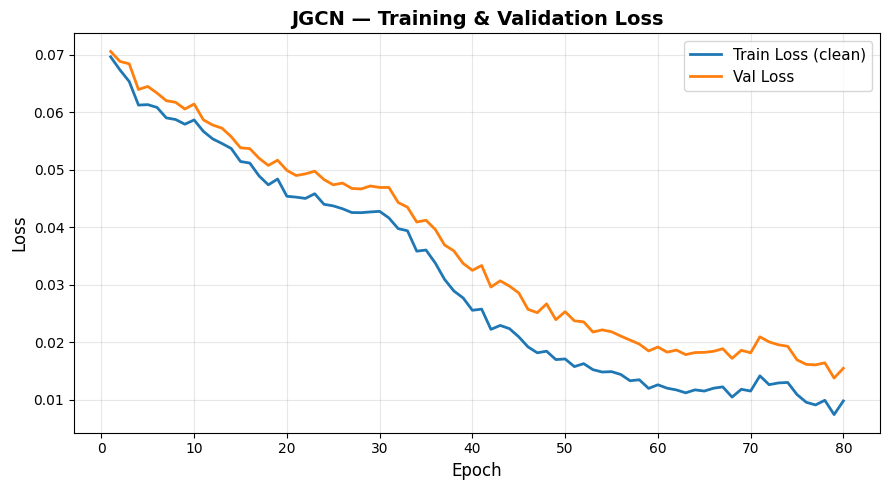

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Loss_Curve.png


In [10]:
# CELL 8A  Training Loss Curve
eps  = [h['ep'] for h in history]
tls  = [h['tl'] for h in history]
vls  = [h['vl'] for h in history]

plt.figure(figsize=(9, 5))
plt.plot(eps, tls, label='Train Loss (clean)', color='#1f77b4', linewidth=2)
plt.plot(eps, vls, label='Val Loss',           color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.title('JGCN — Training & Validation Loss', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Loss_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8B Training Accuracy Curve

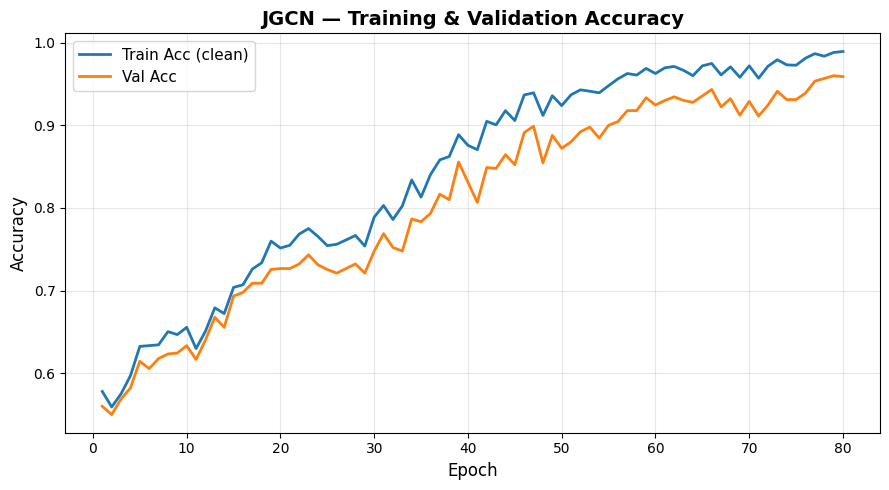

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Accuracy_Curve.png


In [11]:
# CELL 8B  Training Accuracy Curve
tas = [h['ta'] for h in history]
vas = [h['va'] for h in history]

plt.figure(figsize=(9, 5))
plt.plot(eps, tas, label='Train Acc (clean)', color='#1f77b4', linewidth=2)
plt.plot(eps, vas, label='Val Acc',           color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Accuracy', fontsize=12)
plt.title('JGCN — Training & Validation Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Accuracy_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8C  Validation AUC Curve

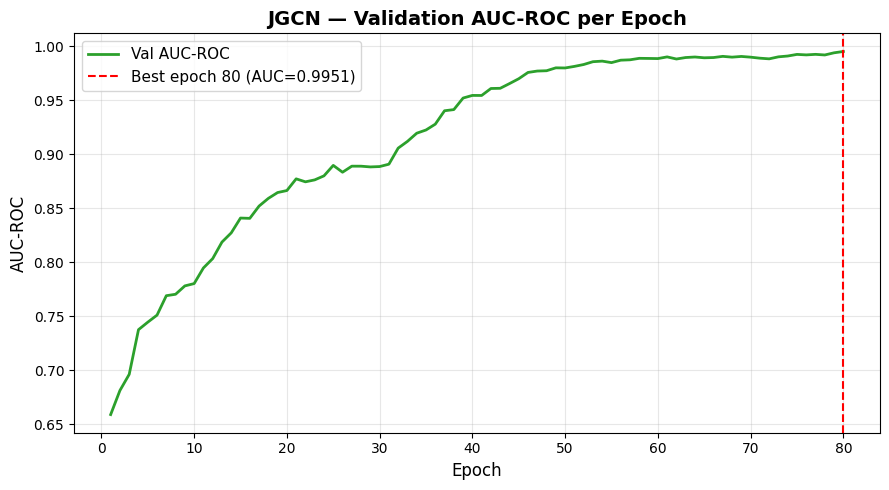

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Validation_AUC_Curve.png


In [12]:
# CELL 8C  Validation AUC Curve
vaucs = [h['vauc'] for h in history]
best_ep = eps[int(np.argmax(vaucs))]

plt.figure(figsize=(9, 5))
plt.plot(eps, vaucs, color='#2ca02c', linewidth=2, label='Val AUC-ROC')
plt.axvline(best_ep, color='red', linestyle='--', linewidth=1.5,
            label=f'Best epoch {best_ep} (AUC={max(vaucs):.4f})')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('AUC-ROC', fontsize=12)
plt.title('JGCN — Validation AUC-ROC per Epoch', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Validation_AUC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8D  Confusion Matrix

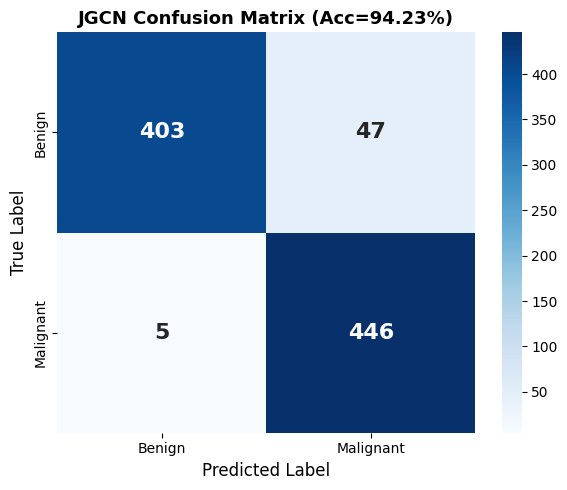

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Confusion_Matrix.png


In [13]:
# CELL 8D  Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar=True, annot_kws={'size': 16, 'weight': 'bold'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.title(f'JGCN Confusion Matrix (Acc={acc*100:.2f}%)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Confusion_Matrix.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8E  ROC Curve

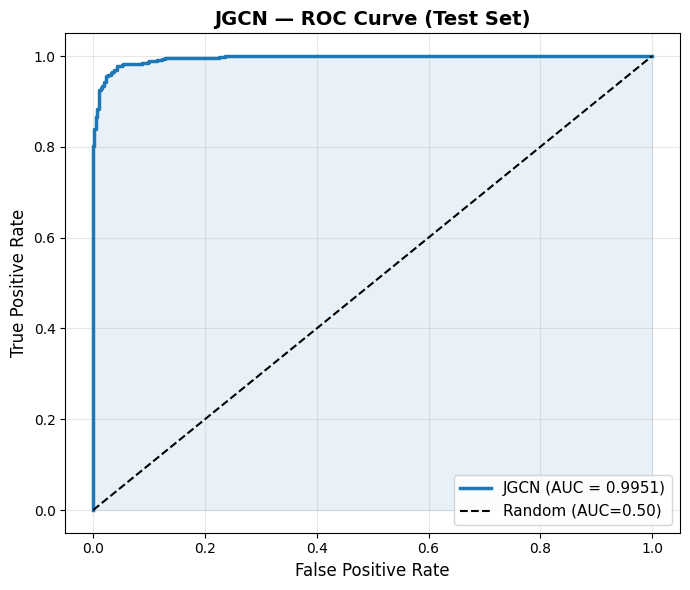

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_ROC_Curve.png


In [14]:
# CELL 8E  ROC Curve
fpr, tpr, _ = roc_curve(all_labels_test, all_probs_test)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#1f77b4', linewidth=2.5,
         label=f'JGCN (AUC = {auc_sc:.4f})')
plt.fill_between(fpr, tpr, alpha=0.1, color='#1f77b4')
plt.plot([0,1],[0,1],'k--', linewidth=1.5, label='Random (AUC=0.50)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate',  fontsize=12)
plt.title('JGCN — ROC Curve (Test Set)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3); plt.tight_layout()

# Save fpr/tpr for comparison plots
jgcn_fpr_saved = fpr.copy()
jgcn_tpr_saved = tpr.copy()

p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_ROC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8F  Precision-Recall Curve

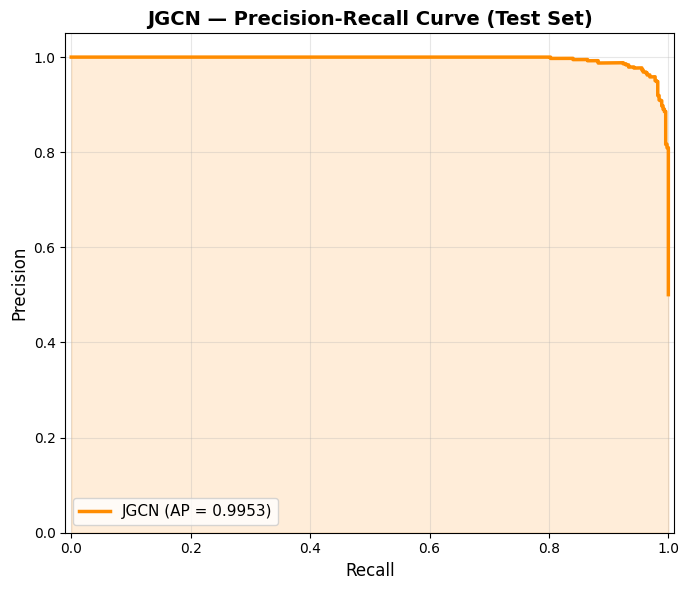

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_PR_Curve.png


In [15]:
# CELL 8F Precision-Recall Curve
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_arr, recall_arr, _ = precision_recall_curve(all_labels_test, all_probs_test)
avg_precision = average_precision_score(all_labels_test, all_probs_test)

plt.figure(figsize=(7, 6))
plt.plot(recall_arr, precision_arr, color='darkorange', linewidth=2.5,
         label=f'JGCN (AP = {avg_precision:.4f})')
plt.fill_between(recall_arr, precision_arr, alpha=0.15, color='darkorange')
plt.xlabel('Recall',    fontsize=12); plt.ylabel('Precision', fontsize=12)
plt.title('JGCN — Precision-Recall Curve (Test Set)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower left')
plt.grid(alpha=0.3); plt.xlim([-0.01,1.01]); plt.ylim([0,1.05])
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_PR_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8G  Sample Inference

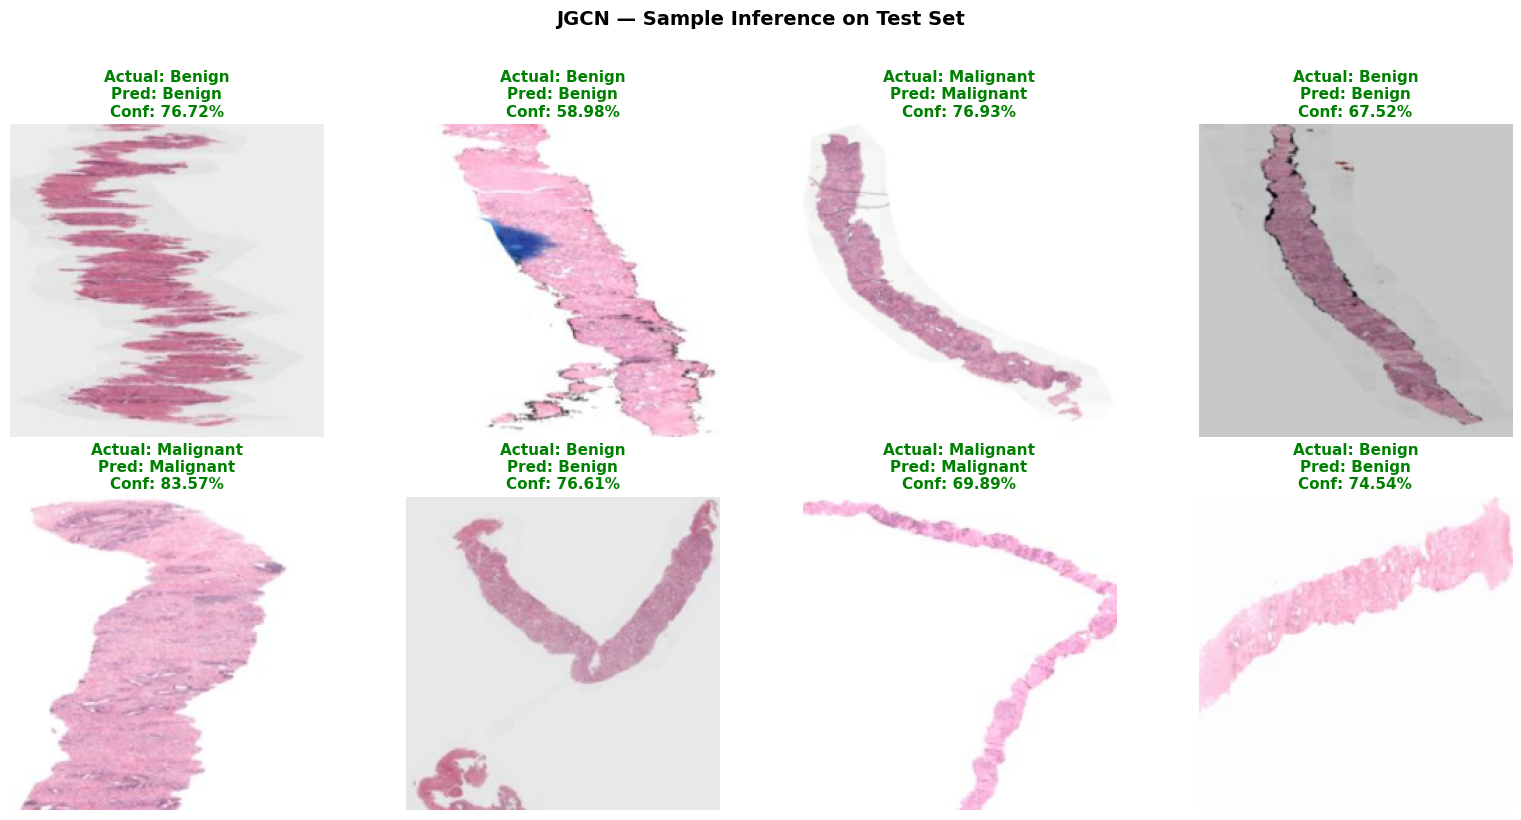

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Sample_Inference.png


In [16]:
# CELL 8G  Sample Inference (8 random test images)
CLASS_NAMES = ['Benign', 'Malignant']

def predict_single(img_tensor, graph):
    model.eval()
    with torch.no_grad():
        g_batch = Batch.from_data_list([graph]).to(DEVICE)
        logits  = model(img_tensor.unsqueeze(0).to(DEVICE), g_batch)
        probs   = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
    return int(np.argmax(probs)), float(probs[np.argmax(probs)])

np.random.seed(42)
sample_indices = np.random.choice(len(test_ds), 8, replace=False)

plt.figure(figsize=(16, 8))
for i, idx in enumerate(sample_indices):
    img_t, graph, label = test_ds[idx]
    pred_idx, confidence = predict_single(img_t, graph)
    is_correct = (pred_idx == int(label))
    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(denormalize(img_t)); ax.axis('off')
    ax.set_title(
        f'Actual: {CLASS_NAMES[int(label)]}\n'
        f'Pred: {CLASS_NAMES[pred_idx]}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color='green' if is_correct else 'red', fontweight='bold'
    )
plt.suptitle('JGCN — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Sample_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8H  Sobel Edge Detection on Sample Inference Images

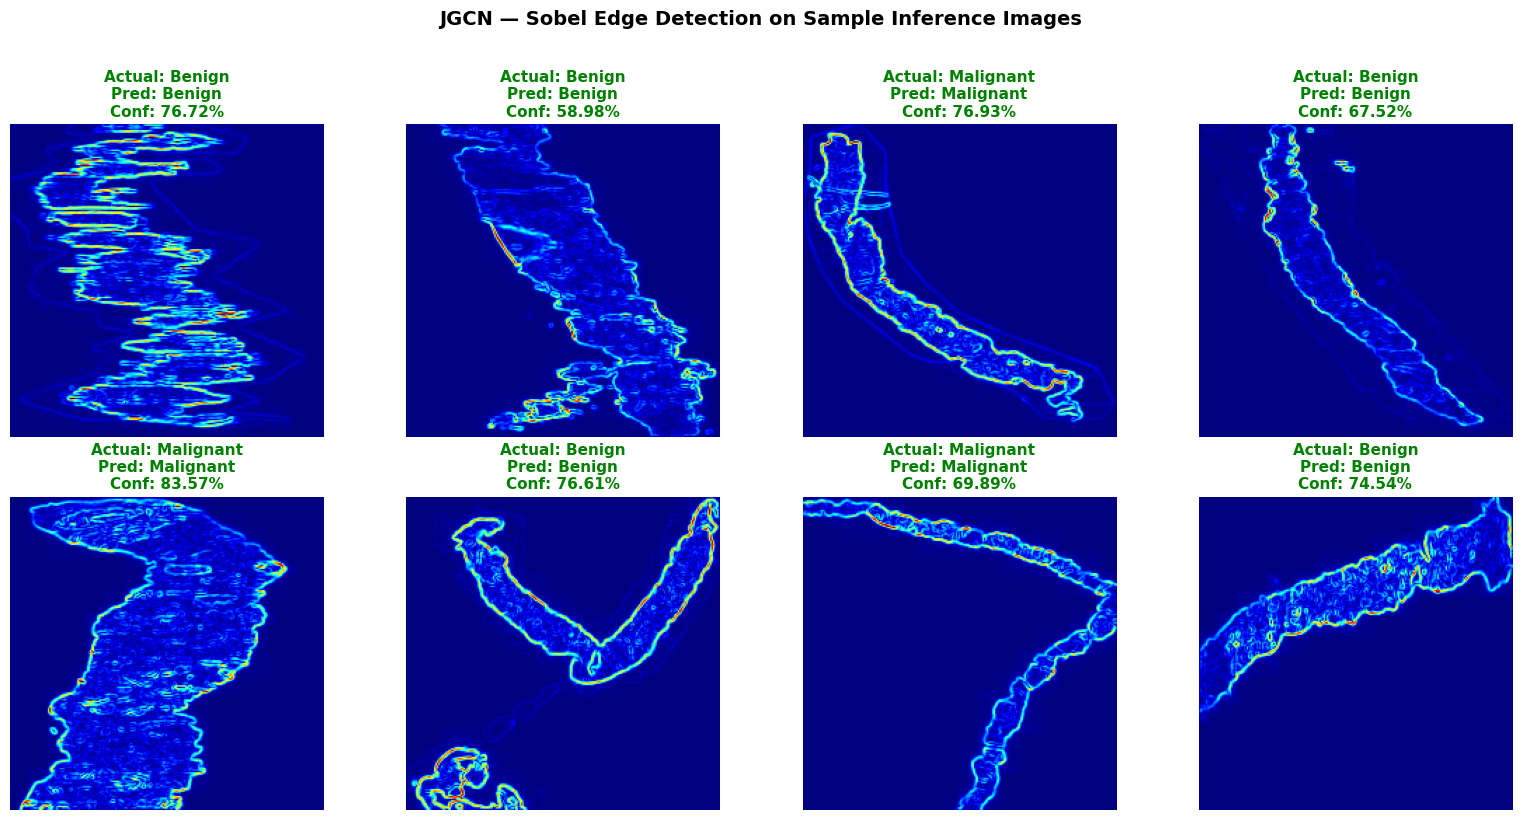

Saved: <repo>/results\Retrain_JGCN_matched\JGCN_matched_Sobel_Edge_Inference.png


In [17]:
# CELL 8H Sobel Edge Detection on Sample Inference Images
plt.figure(figsize=(16, 8))
for i, idx in enumerate(sample_indices):
    img_t, graph, label = test_ds[idx]
    pred_idx, confidence = predict_single(img_t, graph)
    is_correct = (pred_idx == int(label))

    img_display = denormalize(img_t)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    sobel_x     = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y     = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude   = cv2.magnitude(sobel_x, sobel_y)
    mag_norm    = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    edges_rgb   = cv2.cvtColor(cv2.applyColorMap(mag_norm, cv2.COLORMAP_JET),
                               cv2.COLOR_BGR2RGB)

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges_rgb); ax.axis('off')
    ax.set_title(
        f'Actual: {CLASS_NAMES[int(label)]}\n'
        f'Pred: {CLASS_NAMES[pred_idx]}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color='green' if is_correct else 'red', fontweight='bold'
    )
plt.suptitle('JGCN — Sobel Edge Detection on Sample Inference Images',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'JGCN_matched_Sobel_Edge_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## Cell 8L — Canny Edge Detection on Sample Inference Images 

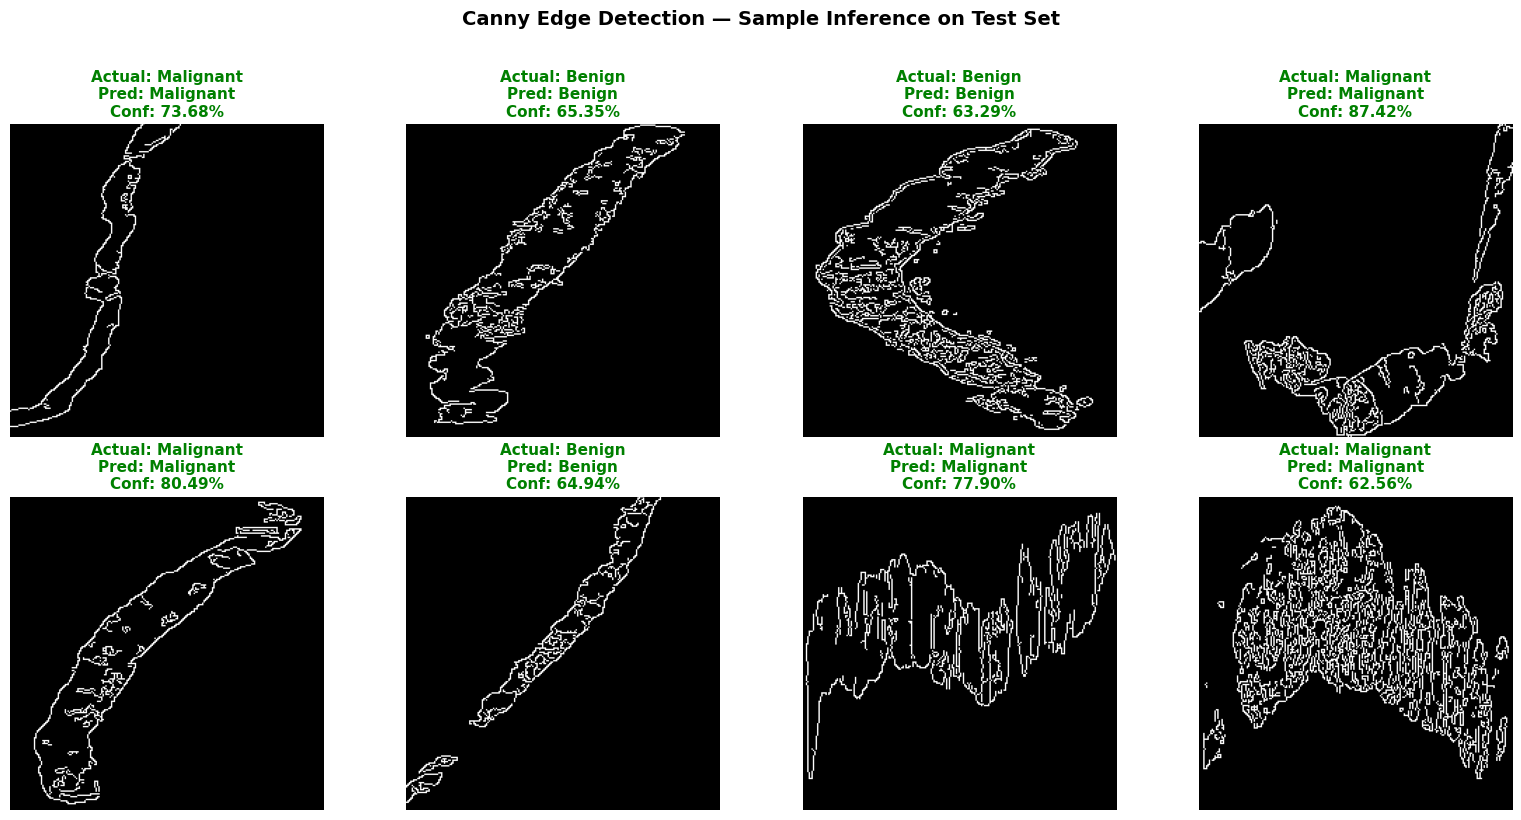


Canny edge maps for 8 random test samples
Saved to: Canny_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [18]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8L — Canny Edge Detection on Sample Inference Images    ║
# ║ Matched to Hybrid Cell 9J format                             ║
# ╚══════════════════════════════════════════════════════════════╝
class_names = ['Benign', 'Malignant']

n_show = 8
sample_idx = np.random.choice(len(all_labels_test), n_show, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, idx in enumerate(sample_idx):
    ax = axes[i // 4, i % 4]

    img_pil = Image.open(all_paths[test_idx][idx]).convert('RGB')
    img_np  = np.array(img_pil.resize((CONFIG['img_size'], CONFIG['img_size'])))
    gray    = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    edges   = cv2.Canny(gray, 50, 150)

    ax.imshow(edges, cmap='gray')
    ax.axis('off')

    actual_class    = class_names[all_labels_test[idx]]
    predicted_class = class_names[all_preds_test[idx]]
    confidence      = all_probs_test[idx] if all_preds_test[idx] == 1 \
                      else 1 - all_probs_test[idx]
    is_correct      = all_labels_test[idx] == all_preds_test[idx]

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11,
        color=title_color,
        fontweight='bold'
    )

plt.suptitle('Canny Edge Detection — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'Canny_Edge_Inference.png'),
            dpi=600, bbox_inches='tight')
plt.show()

print(f'\nCanny edge maps for {n_show} random test samples')
print(f'Saved to: Canny_Edge_Inference.png')
print(f'Green title = correct prediction | Red title = incorrect')


## Cell 8M — Morphological Operations on Canny Edge Maps 

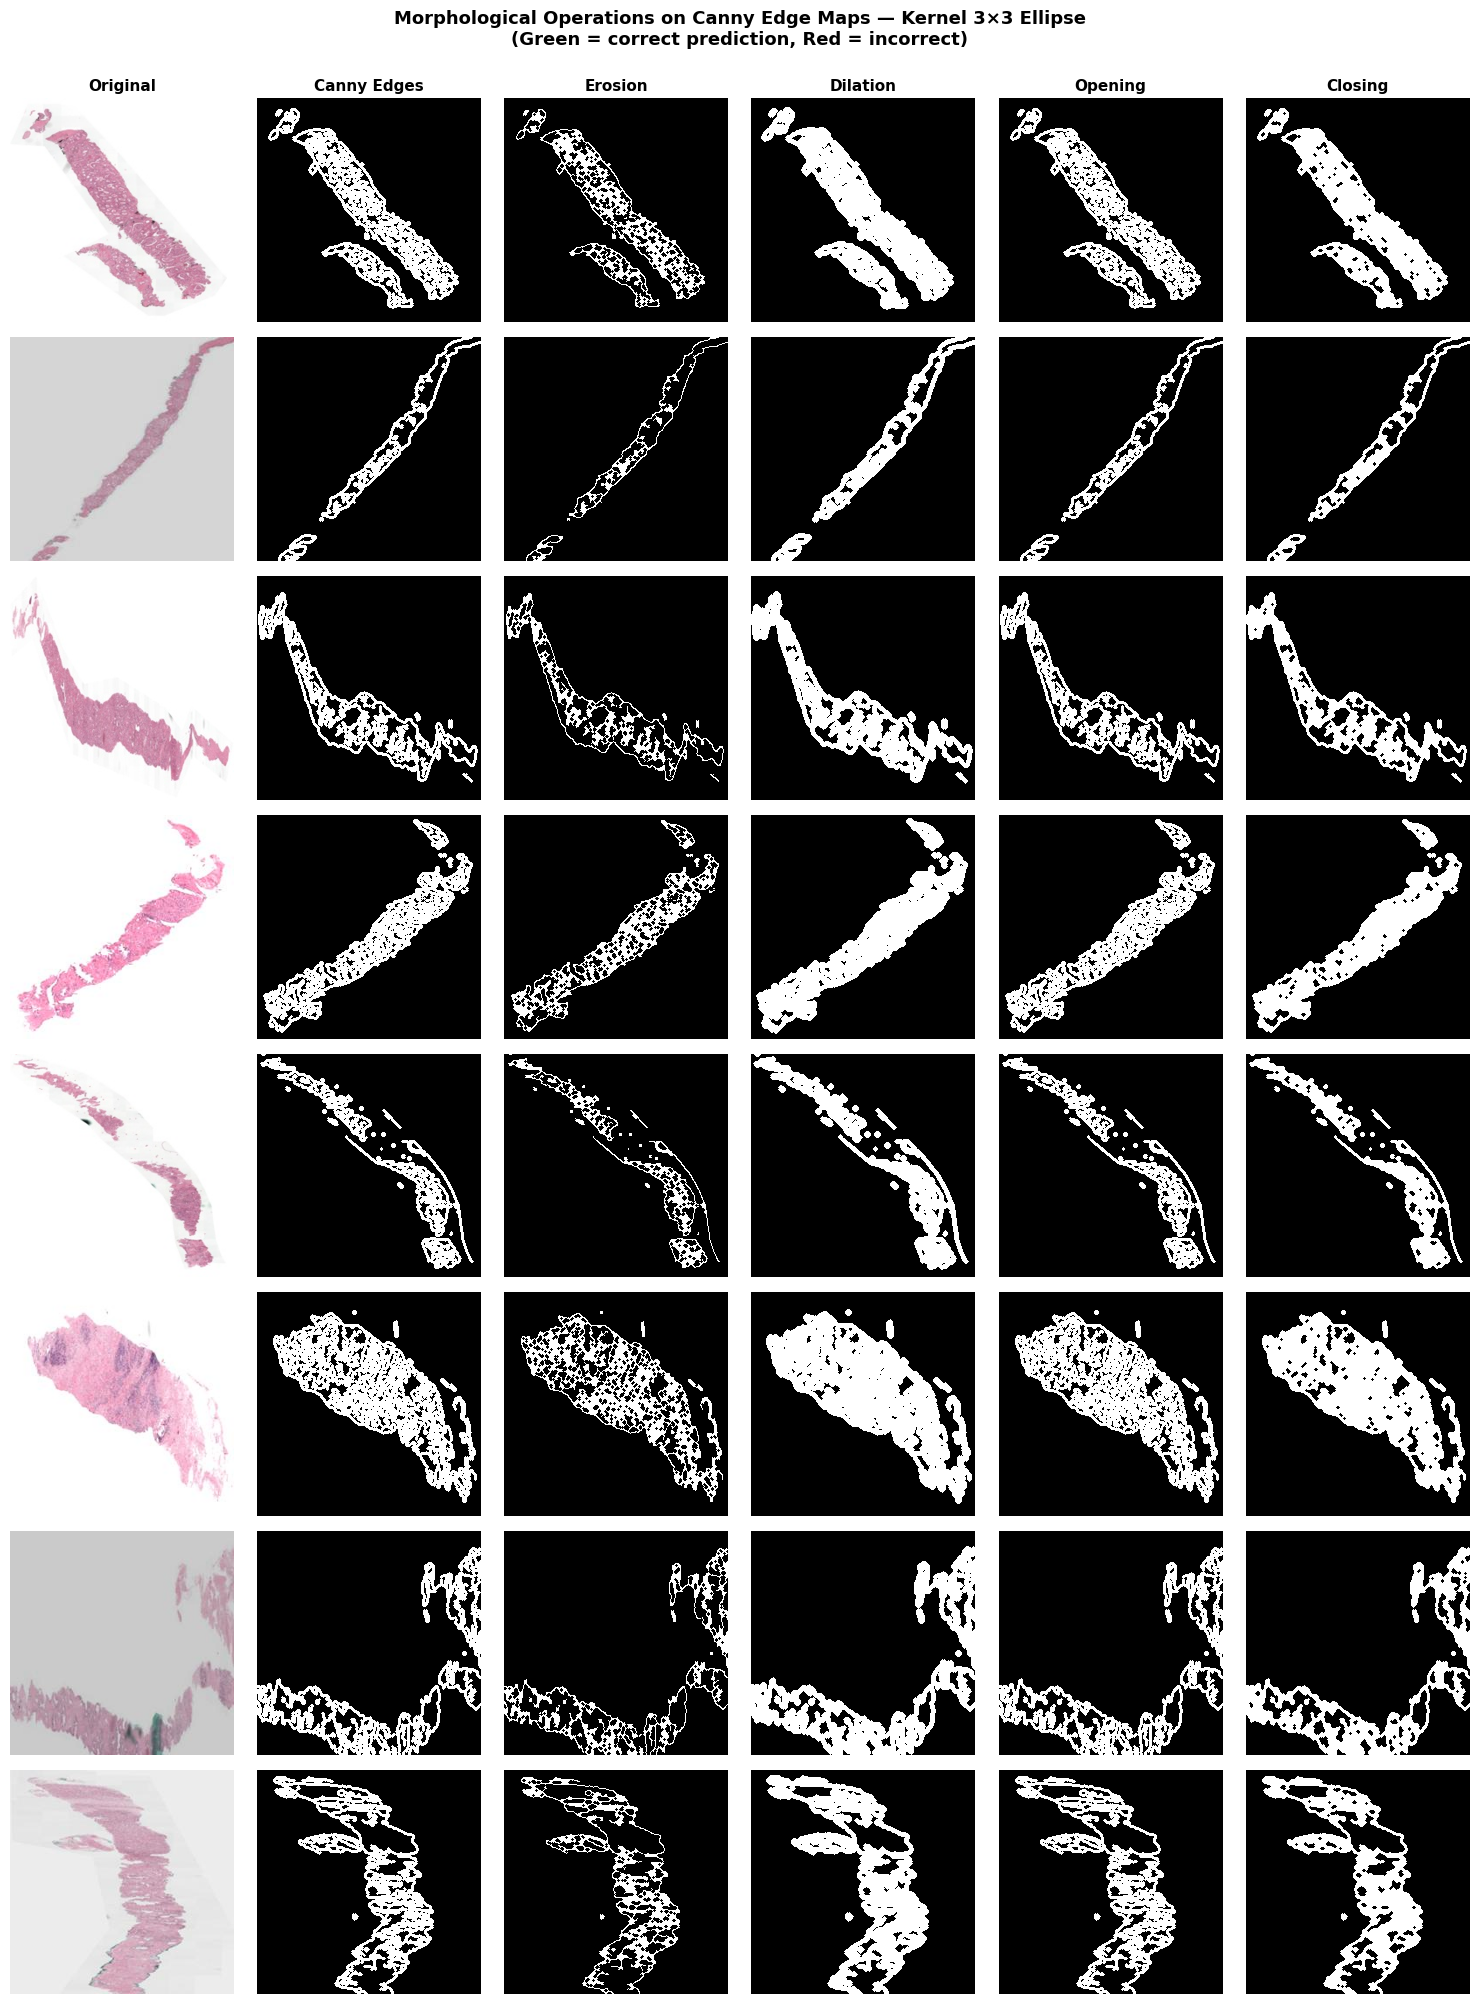


Saved to: Morphological_Canny.png


In [19]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8M — Morphological Operations on Canny Edge Maps        ║
# ║ Matched to Hybrid Cell 9L format                             ║
# ╚══════════════════════════════════════════════════════════════╝
class_names = ['Benign', 'Malignant']

n_show = 8
sample_idx = np.random.choice(len(all_labels_test), n_show, replace=False)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

col_titles = ['Original', 'Canny Edges', 'Erosion', 'Dilation', 'Opening', 'Closing']

fig, axes = plt.subplots(n_show, 6, figsize=(15, n_show*2.5))
for row, idx in enumerate(sample_idx):
    img_pil = Image.open(all_paths[test_idx][idx]).convert('RGB')
    img_np  = np.array(img_pil.resize((CONFIG['img_size'], CONFIG['img_size'])))
    gray    = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)

    canny_raw = cv2.Canny(gray, 30, 100)              # lower thresholds = denser edges
    canny     = cv2.dilate(canny_raw, kernel, iterations=1)  # thicken to match hybrid
    erosion   = cv2.erode(canny, kernel, iterations=1)
    dilation  = cv2.dilate(canny, kernel, iterations=1)
    opening   = cv2.morphologyEx(canny, cv2.MORPH_OPEN,  kernel)
    closing   = cv2.morphologyEx(canny, cv2.MORPH_CLOSE, kernel)

    axes[row, 0].imshow(img_np)
    axes[row, 1].imshow(canny,    cmap='gray')
    axes[row, 2].imshow(erosion,  cmap='gray')
    axes[row, 3].imshow(dilation, cmap='gray')
    axes[row, 4].imshow(opening,  cmap='gray')
    axes[row, 5].imshow(closing,  cmap='gray')

    # Column headers only on first row
    if row == 0:
        for c, t in enumerate(col_titles):
            axes[row, c].set_title(t, fontsize=11, fontweight='bold')

    for c in range(6):
        axes[row, c].axis('off')

    # Green/red side label showing correctness
    is_correct = all_labels_test[idx] == all_preds_test[idx]
    color = 'green' if is_correct else 'red'
    actual_class = class_names[all_labels_test[idx]]
    pred_class   = class_names[all_preds_test[idx]]
    axes[row, 0].set_ylabel(
        f'{actual_class} → {pred_class}',
        fontsize=9,
        color=color,
        fontweight='bold',
        rotation=0,
        labelpad=45,
        va='center'
    )

plt.suptitle(
    'Morphological Operations on Canny Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=13, fontweight='bold', y=1.00
)
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'Morphological_Canny.png'),
            dpi=300, bbox_inches='tight')
plt.show()

print(f'\nSaved to: Morphological_Canny.png')

## Cell 8I  Final Performance Summary

In [20]:
# CELL 8I  Final Performance Summary
print('═' * 60)
print('CLASSIFICATION REPORT — Test Set')
print('═' * 60)
print(classification_report(all_labels_test, all_preds_test,
                            target_names=['Benign', 'Malignant'], digits=4))
print('═' * 60)
print(f'Accuracy    :  {acc:.4f}  ({acc*100:.2f}%)')
print(f'AUC-ROC     :  {auc_sc:.4f}')
print(f'F1 Score    :  {f1:.4f}')
print(f'Precision   :  {prec:.4f}')
print(f'Recall      :  {rec:.4f}')
print(f'MCC         :  {mcc:.4f}')
print(f'Sensitivity :  {sensitivity:.4f}')
print(f'Specificity :  {specificity:.4f}')
print('═' * 60)
print()
print('Joint Graph design summary:')
print(f'  Graph type       : Joint spatial + cosine similarity')
print(f'  Spatial thresh   : {CONFIG["spatial_thresh"]} (Manhattan grid distance)')
print(f'  Sim thresh       : {CONFIG["sim_thresh"]} (cosine similarity)')
print(f'  GCN dim          : {CONFIG["jgcn_hidden_dim"]} (vs LGCN 256)')
print(f'  GCN layers       : {CONFIG["jgcn_layers"]} (vs LGCN 3)')
print(f'  CNN freeze depth : blocks 0-4 (MATCHED to LGCN/GAT/Hybrid — confound removed)')
print()
print('All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('  JGCN_Loss_Curve.png')
print('  JGCN_Accuracy_Curve.png')
print('  JGCN_Validation_AUC_Curve.png')
print('  JGCN_Confusion_Matrix.png')
print('  JGCN_ROC_Curve.png')
print('  JGCN_PR_Curve.png')
print('  JGCN_Sample_Inference.png')
print('  JGCN_Sobel_Edge_Inference.png')


════════════════════════════════════════════════════════════
CLASSIFICATION REPORT — Test Set
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Benign     0.9877    0.8956    0.9394       450
   Malignant     0.9047    0.9889    0.9449       451

    accuracy                         0.9423       901
   macro avg     0.9462    0.9422    0.9422       901
weighted avg     0.9462    0.9423    0.9422       901

════════════════════════════════════════════════════════════
Accuracy    :  0.9423  (94.23%)
AUC-ROC     :  0.9951
F1 Score    :  0.9422
Precision   :  0.9462
Recall      :  0.9423
MCC         :  0.8884
Sensitivity :  0.9889
Specificity :  0.8956
════════════════════════════════════════════════════════════

Joint Graph design summary:
  Graph type       : Joint spatial + cosine similarity
  Spatial thresh   : 1.5 (Manhattan grid distance)
  Sim thresh       : 0.75 (cosine similarity)
  GCN dim          : 256 (vs 